**See the correctness of the expert predicitions**

In [1]:
def predicition_results(team_id, results):
    ratio_list_1 = []
    dates_list = []
    date_count = 1
    # Print the results
    for date, matches in results.items():
        #print(f"Date: {date}")
        correct, wrong = 0, 0
        for match in matches:
            if match[2] > match[6]:
                actual_winner = match[0]
            else:
                actual_winner = match[4]
            
            if match[8] == actual_winner:
                correct += 1
            else:
                wrong += 1
        ratio = correct / (correct + wrong)
        ratio_list_1.append(ratio)
        
        dates_list.append(date_count)
        date_count += 1
        
        #print()
    
    plt.plot(dates_list, ratio_list_1, label='Expert Prediction Accuracy')
    plt.xlabel('Date Count')
    plt.ylabel('Accuracy Ratio')
    plt.title('Prediction Results Over Time')
    plt.legend()
    plt.show()

**See the correctness of the sportsbook predicitions**

In [2]:
def sportbook_predictions(team_id, results):
    ratio_list_2 = []
    dates_list = []
    date_count = 1
    # Print the results
    for date, matches in results.items():
        #print(f"Date: {date}")
        correct, wrong = 0, 0
        for match in matches:
            
            if match[2] > match[6]:
                actual_winner = match[0]
            else:
                actual_winner = match[4]
            
            if '-' in match[3]:
                predicted_winner = match[0]
            else:
                predicted_winner = match[4]
                
            if predicted_winner == actual_winner:
                correct += 1
            else:
                wrong += 1
                
        ratio = correct / (correct + wrong)
        ratio_list_2.append(ratio)
        
        dates_list.append(date_count)
        date_count += 1
        
        #print()
    
    plt.plot(dates_list, ratio_list_2, label='Sports Book Prediction Accuracy')
    plt.xlabel('Date Count')
    plt.ylabel('Accuracy Ratio')
    plt.title('Prediction Results Over Time')
    plt.legend()
    plt.show()

In [3]:
def team_specific_predictions(team_id, results):
    
    a_correct, a_wrong = 0, 0
    p_correct, p_wrong = 0, 0
    
    for date, matches in results.items():
        #print(f"Date: {date}")
        
        for match in matches:
            
            if match[0] == team_id or match[4] == team_id:
                if match[2] > match[6]:
                    actual_winner = match[0]
                else:
                    actual_winner = match[4]
                
                if '-' in match[3]:
                    predicted_winner = match[0]
                else:
                    predicted_winner = match[4]
                  
                if team_id == actual_winner:
                    a_correct += 1
                else:
                    a_wrong += 1
                      
                if team_id == predicted_winner:
                    p_correct += 1
                else:
                    p_wrong += 1
                    
    values = [a_correct, a_wrong, p_correct, p_wrong]
    # values = [10, 20, 30, 40]
    labels = ['Actual Correct', 'Actual Wrong', 'Predicted Correct', 'Predicted Wrong']

    plt.figure(figsize=(10, 6))
    plt.bar(labels, values, color=['blue', 'red', 'green', 'orange'])
    
    # Add labels and title
    plt.xlabel('Categories')
    plt.ylabel('Count')
    plt.title('Histogram of Correct and Wrong Predictions')
    
    # Display the plot
    plt.show()

**See the correctness when sportsbook and predictions pick the same winner**

In [4]:
def sportsbook_expert_prediction(team_id, results):
    ratio_list_3 = []
    dates_list = []
    date_count = 1
    # Print the results
    for date, matches in results.items():
        #print(f"Date: {date}")
        combined, correct, wrong = 0, 0, 0
        for match in matches:
            if match[2] > match[6]:
                actual_winner = match[0]
            else:
                actual_winner = match[4]
            
            if '-' in match[3]:
                predicted_winner_sportsbook = match[0]
            else:
                predicted_winner_sportsbook = match[4]
                
            if predicted_winner_sportsbook == match[8]:
                combined += 1
            
            if predicted_winner_sportsbook == match[8] == actual_winner:
                correct += 1
            else:
                wrong += 1
                
        try:
            ratio = correct / combined
        except ZeroDivisionError:
            ratio = 0
        ratio_list_3.append(ratio)
        
        dates_list.append(date_count)
        date_count += 1
        
        #print()
    
    plt.plot(dates_list, ratio_list_3, label='Sportbook + Expert Prediction Accuracy')
    plt.xlabel('Date Count')
    plt.ylabel('Accuracy Ratio')
    plt.title('Prediction Results Over Time')
    plt.legend()
    plt.show()

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

file_path = 'scraped_ncaa_scores.csv'
data = pd.read_csv(file_path)

extracted_data = data[['Date', 'Team_1_id', 'Team_1_name', 'Team_1_score', 'Team_1_spread', 'Team_2_id', 'Team_2_name', 'Team_2_score','Team_2_spread', 'Predicted_winner_id','Predicted_winner_name']]

unique_dates = extracted_data['Date'].unique()

# Initialize a dictionary to store the results
results = {}

# Iterate through each unique date
for date in unique_dates:
    filtered_data = extracted_data[extracted_data['Date'] == date]
    matches = list(zip(filtered_data['Team_1_id'], filtered_data['Team_1_name'], filtered_data['Team_1_score'],
                    filtered_data['Team_1_spread'],filtered_data['Team_2_id'], filtered_data['Team_2_name'], filtered_data['Team_2_score'], filtered_data['Team_2_spread'],
                       filtered_data['Predicted_winner_id'], filtered_data['Predicted_winner_name']))
    results[date] = matches
print(f'match[0]: Team_1_id\nmatch[1]: Team_1_name\nmatch[2]: Team_1_score\nmatch[3]: Team_1_spread\nmatch[4]: Team_2_id\nmatch[5]: Team_2_name\nmatch[6]: Team_2_score\nmatch[7]: Team_2_spread\nmatch[8]: Predicted_winner_id\nmatch[9]: Predicted_winner_name\n')

match[0]: Team_1_id
match[1]: Team_1_name
match[2]: Team_1_score
match[3]: Team_1_spread
match[4]: Team_2_id
match[5]: Team_2_name
match[6]: Team_2_score
match[7]: Team_2_spread
match[8]: Predicted_winner_id
match[9]: Predicted_winner_name


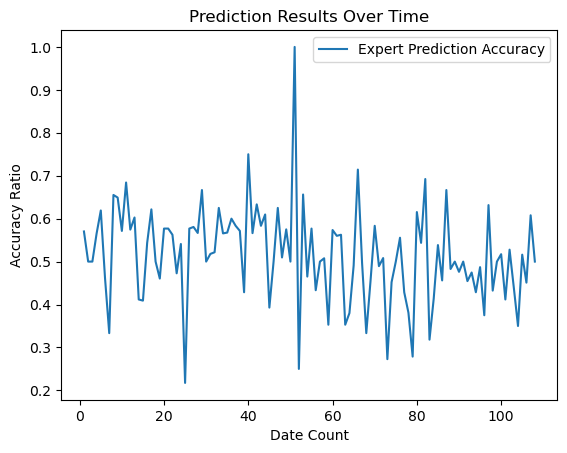

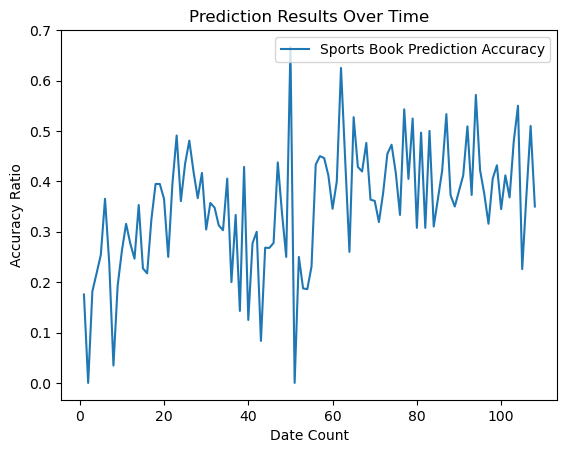

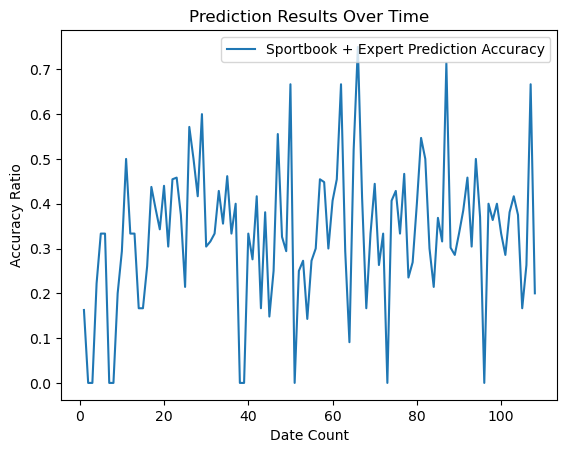

In [6]:
#plot the results
predicition_results(None, results)
sportbook_predictions(None, results)
sportsbook_expert_prediction(None, results)